# 04 — Bespoke Conventional CNN

Prepare the five-block 28-input architecture as a separate experiment. This model
has not been trained. The defaults below match the three-epoch warm-up procedure;
results will use a new group and distinct `bespoke28` artifact names.


In [ ]:
from pathlib import Path
import sys
import importlib
from IPython.display import Image, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from scripts.model import digit_model_experiments as experiments


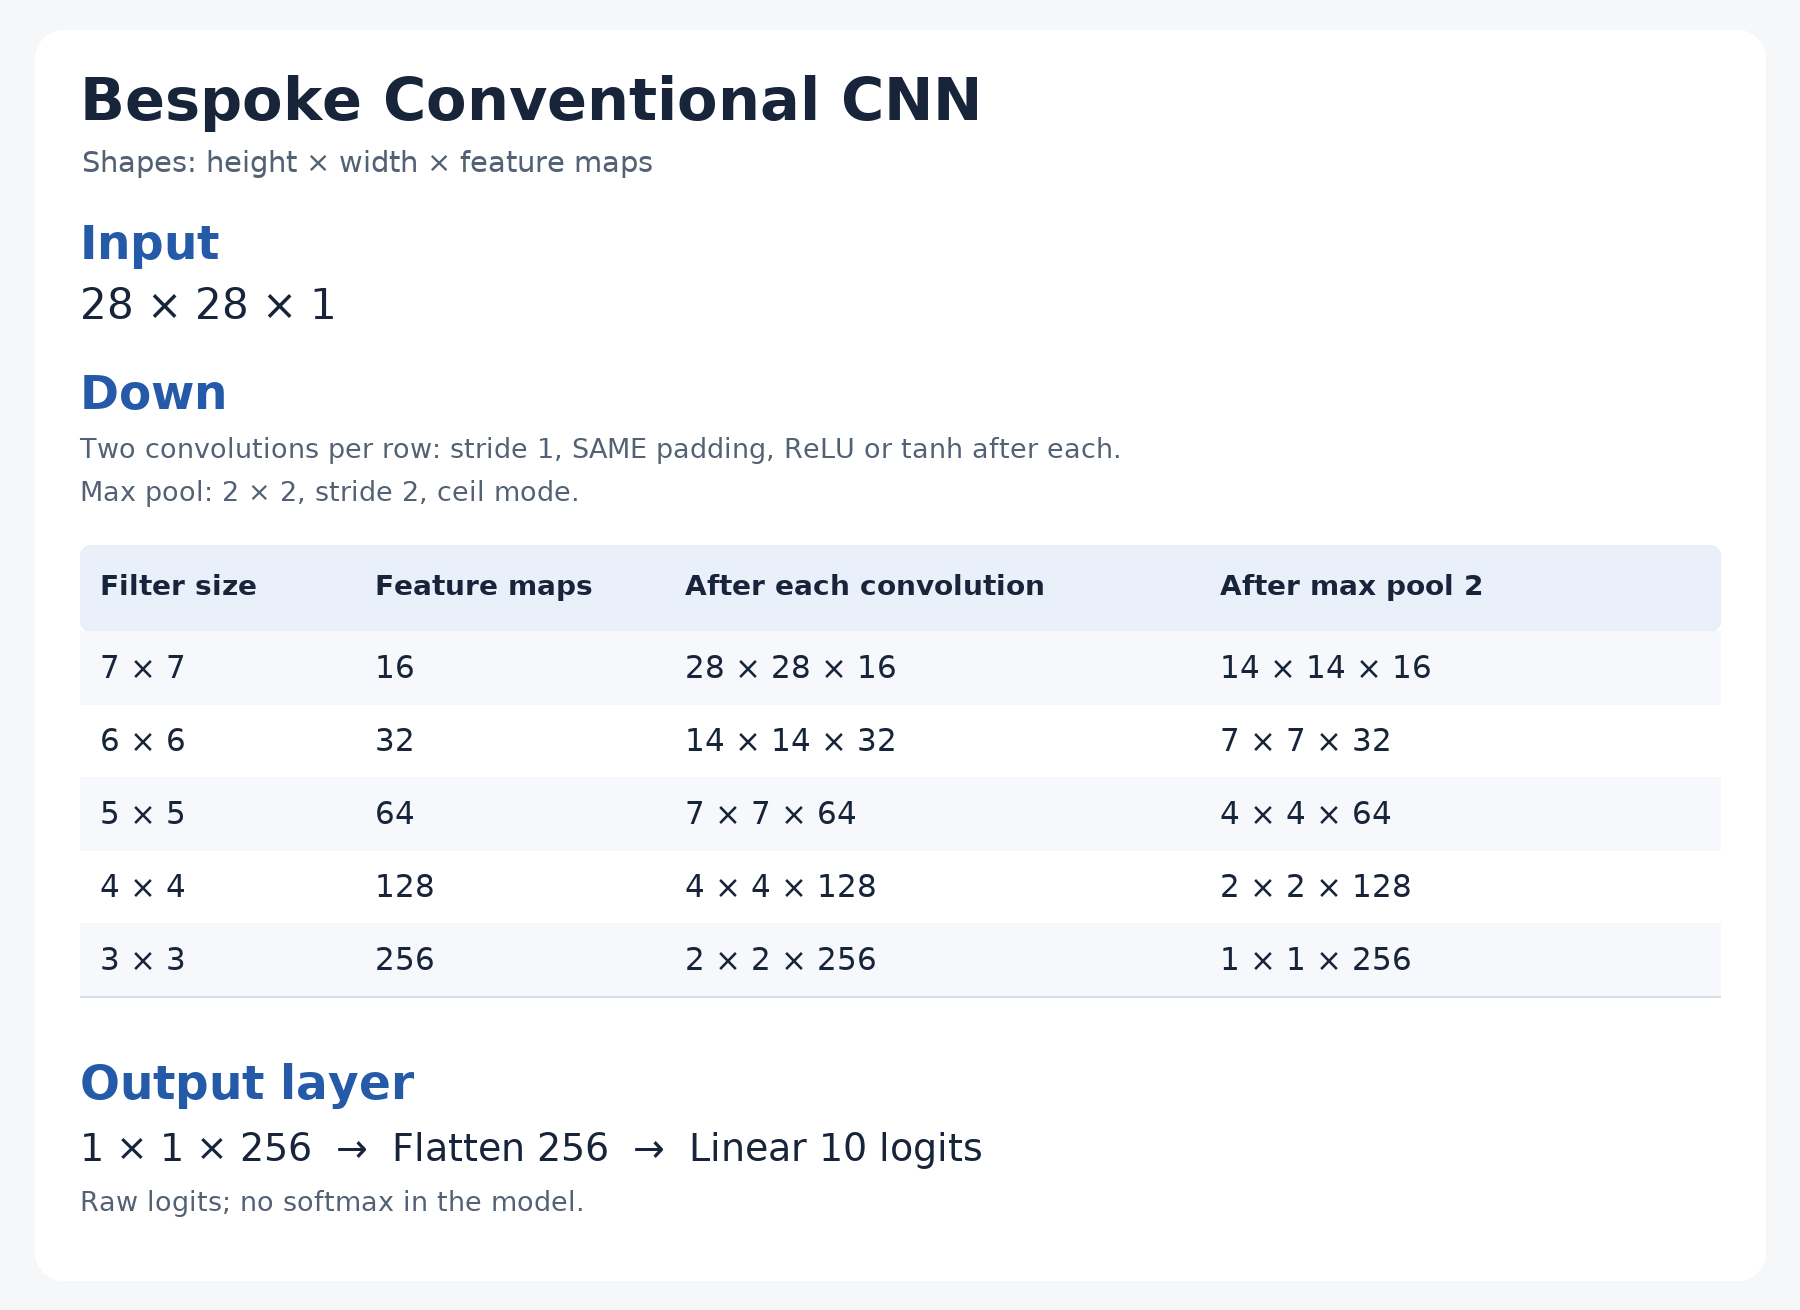

In [ ]:
display(Image(filename=str(project_root / "docs/evaluations/assets/bespoke-conventional-architecture.png"), width=480))


## Experiment settings


In [ ]:
MODEL_NAME = "bespoke"
EPOCHS = 3
LEARNING_RATES = (1e-6, 1e-5, 1e-4, 1e-3)
WARMUP_FRACTION = 0.10
WEIGHT_DECAY = 0.0
ACTIVATIONS = ("relu", "tanh")
SEED = 42
BATCH_SIZE = 64
VALIDATION_FRACTION = 0.2
SWEEP_DIRECTORY = None  # Allocate a new unique group only on manual training.


## Inspect data and model


In [ ]:
experiments.show_dataset_summary()
experiments.inspect_bespoke_model(activation=ACTIVATIONS[0], seed=SEED, model_name=MODEL_NAME)


## Train only when ready

The next cell starts serial training only when deliberately executed. No training
was run while preparing this notebook. Both activations run at each target rate;
each starts with the matched seed/split/order. Warm-up reaches target at update
158 of 1,575, then holds it. Existing experiment groups and notebook 03 remain
separate. Active managed-run locks prevent overlapping work.


In [ ]:
assert ACTIVATIONS == ("relu", "tanh")
assert SEED == 42 and BATCH_SIZE == 64 and VALIDATION_FRACTION == 0.2
SWEEP_DIRECTORY = experiments.run_bespoke_sweep(
    epochs=EPOCHS, learning_rates=LEARNING_RATES,
    warmup_fraction=WARMUP_FRACTION, weight_decay=WEIGHT_DECAY,
    sweep_directory=SWEEP_DIRECTORY, model_name=MODEL_NAME,
)


## Results

Select this notebook's own saved results directory to review completed runs,
tables, comparisons, and capped galleries. This cell reads saved outputs without
training or model inference. No results exist yet for this prepared architecture.


In [ ]:
experiments = importlib.reload(experiments)
experiments.refresh_helpers()
experiments.show_results(SWEEP_DIRECTORY)
